# Same Policy, 50% Faster: The Contact Law Was the Model

Walking speed against the sole friction coefficient, in the Modelica plant and in MuJoCo.

[Setup and files](README.md).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))
from common import *  # noqa: F403  FMU and MuJoCo helpers, plot style

%matplotlib inline

In [2]:
FRICTIONS = [0.3, 0.5, 1.0, 2.0]
rows = []
for mu in FRICTIONS:
    duck = walk_fmu(friction=mu)  # about a minute each
    mj = walk_mujoco(friction=mu)
    fallen = duck["time"][duck["trunkHeight"] < 0.09]
    rows.append({"friction": mu, "Duck library [m/s]": np.nan if len(fallen) else speed(duck),
                 "Duck falls at [s]": fallen.iloc[0] if len(fallen) else np.nan, "MuJoCo [m/s]": speed(mj)})
table = pd.DataFrame(rows).set_index("friction")
table.round(3)

Stopped at t = 0.89 s: the robot has fallen and the solution diverges


,Duck library [m/s],Duck falls at [s],MuJoCo [m/s]
friction,,,
0.3,NaN,0.424,0.092
0.5,0.140,NaN,0.133
1.0,0.138,NaN,0.132
2.0,0.149,NaN,0.122


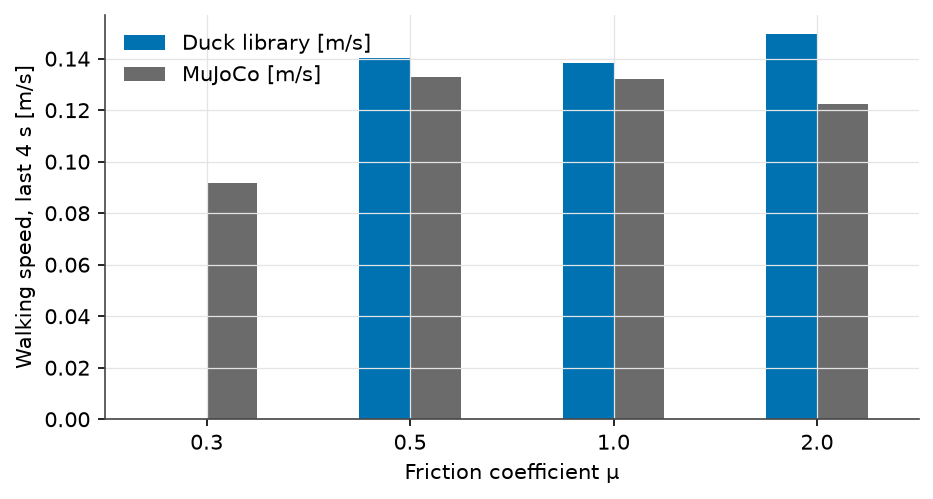

In [3]:
ax = table[["Duck library [m/s]", "MuJoCo [m/s]"]].plot.bar(rot=0, color=[BLUE, GREY], figsize=(7, 3.5))
ax.set_ylabel("Walking speed, last 4 s [m/s]"); ax.set_xlabel("Friction coefficient μ")
plt.show()